# ColorMNIST Ablation: Dropping the Autoencoder Split, and Nystrom DR on the Full Sample

Two changes, motivated by the same observation. The reference pipeline spends half the
logged sample on the autoencoder and then caps the DR support at $N_{\mathrm{DR}} =
4000$ rows of the other half — and the sample-size sweep saturates at
$n_{\mathrm{obs}} = 10000$ for exactly that reason: past that point the extra data
never reaches the estimator.

1. **Reuse the autoencoder rows.** The split was insurance against the feature map
   adapting to the estimation sample. It was measured and found nearly free
   (held-out reconstruction MSE $0.0025$ against an in-sample $0.0025$), so the
   insurance may be costing more than the risk. Cross-fitting of the propensity and
   the CME ridge is kept either way — that is what the one-step estimator actually
   requires.
2. **Nystrom for the DR solve.** Lifting $N_{\mathrm{DR}}$ to the whole sample makes
   each fold's ridge solve a $16000 \times 16000$ system, which is not affordable
   exactly. `cpme_dr_weights_crossfit_nystrom` approximates $K_{TT}$ by
   $U K_{LL}^{-1} U^\top$ on $m$ landmarks and applies Woodbury, costing
   $O(|T| m^2 + m^3)$ and never forming a $|T| \times |T|$ matrix. With landmarks
   equal to the training block it reproduces the exact solver to $10^{-10}$.

The design is a $2 \times 2$: $\{$split, no split$\} \times \{N_{\mathrm{DR}} = 4000$
exact, full-sample Nystrom$\}$, over 3 data seeds and both arms, everything else at
the reference configuration.

In [1]:
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import torch

sys.path.append("../../src")
torch.set_default_dtype(torch.float32)

from data_utils import (color_ratio, load_digit_pools, sample_interventional,
                        sample_observed, to_image_range, to_model_range)
from autoencoder_utils import encode_in_batches, train_conv_ae
from kernel_utils import IMQKernel, RBF, imq_c_from_median
from causality_utils import (cpme_dr_weights_crossfit, cpme_dr_weights_crossfit_nystrom,
                             make_crossfit_fold_ids, select_regularization)
from dens_ratio_utils import crossfit_propensity
from mmd_flow_utils import mmd_gradient_flow
from metric_utils import sliced_wasserstein

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
N_OBS, W_CONF, TAU, ALPHA, K_MASK = 20000, 10.0, 0.08, 0.0, 10.0
M, N_DR_SMALL, N_LANDMARKS, N_FOLDS = 1600, 4000, 1024, 5
SEEDS = (0, 1, 2)
print("device:", device)

device: cuda


## 1. One Pipeline, Four Configurations

`run(seed, split_ae, use_nystrom)` differs from the reference script only in which
rows train the autoencoder and how the DR weights are solved. The Gram blocks are
built on demand from closures — `K = K_X \odot K_A` and
$K_\pi[i,j] = K_X[i,j]\,\mathbb 1\{a_i = a\}$ — so the full $20000^2$ matrix is never
materialised.

The ridge parameter is selected per fold on a 2000-row subsample of that fold's
training block: selecting it on the full block would itself cost a
$16000 \times 16000$ solve, and $\lambda$ does not need that resolution.

In [2]:
pools = load_digit_pools(root="../../data", device=device)


def build_data(seed):
    generator = torch.Generator(device=device).manual_seed(seed)
    X, A, Y = sample_observed(pools, N_OBS, w_conf=W_CONF, tau=TAU, alpha=ALPHA,
                              k_mask=K_MASK, generator=generator)
    return X, A, to_model_range(Y)


def train_ae(data, rows, seed):
    ae, _ = train_conv_ae(data[rows], latent_dim=32, n_iterations=3000, batch_size=128,
                          learning_rate=1e-3, device=device,
                          generator=torch.Generator(device=device).manual_seed(seed),
                          log_every=1500, verbose=False)
    for parameter in ae.parameters():
        parameter.requires_grad_(False)
    return ae


def dr_weights(X_s, A_s, Z_s, target_a, seed, use_nystrom):
    "Cross-fitted DR weights; exact solve on the subsample, or Nystrom on all of it."
    n = len(A_s)
    fold_ids = make_crossfit_fold_ids(n, n_folds=N_FOLDS, seed=0)
    torch.manual_seed(seed)
    e1 = crossfit_propensity(X_s.unsqueeze(1).double().cpu(), A_s.double().cpu(), fold_ids)
    w_hat = (A_s.cpu() == target_a).double() / (e1 if target_a == 1 else 1.0 - e1)

    kernel_x = RBF(use_length_scale_heuristic=True)
    anchor = torch.randperm(n, generator=torch.Generator().manual_seed(0))[:4000]
    _ = kernel_x(X_s[anchor].unsqueeze(1).double().cpu())      # lock the lengthscale once
    X_cpu, A_cpu = X_s.unsqueeze(1).double().cpu(), A_s.cpu()
    on_arm_flag = (A_cpu == target_a).double()

    def gram(rows, cols):
        rows, cols = np.asarray(rows), np.asarray(cols)
        k_x = kernel_x(X_cpu[rows], X_cpu[cols])
        return k_x * (A_cpu[rows][:, None] == A_cpu[cols][None, :]).double()

    def gram_pi(rows, cols):
        rows, cols = np.asarray(rows), np.asarray(cols)
        return kernel_x(X_cpu[rows], X_cpu[cols]) * on_arm_flag[rows][:, None]

    # per-fold lambda on a 2000-row subsample of the training block
    fold_lambdas = {}
    for fold in np.unique(fold_ids):
        train = np.where(fold_ids != fold)[0]
        pick = train[torch.randperm(len(train),
                                    generator=torch.Generator().manual_seed(0))[:2000].numpy()]
        fold_lambdas[int(fold)], _ = select_regularization(gram(pick, pick),
                                                           Z_s[pick, 0].double().cpu(), seed=0)
    if use_nystrom:
        v = cpme_dr_weights_crossfit_nystrom(
            gram, gram_pi, w_hat, fold_ids, fold_lambdas, n_landmarks=N_LANDMARKS,
            generator=torch.Generator().manual_seed(seed))
    else:
        K_a_full = (A_cpu[:, None] == A_cpu[None, :]).double()
        v = cpme_dr_weights_crossfit(kernel_x(X_cpu, X_cpu), K_a_full,
                                     on_arm_flag[:, None].expand(n, n).contiguous(),
                                     w_hat, fold_ids, fold_lambdas)
    return v.float().to(device), w_hat


def run(seed, split_ae, use_nystrom):
    "One configuration; returns a row per arm."
    X, A, data = build_data(seed)
    if split_ae:
        order = torch.randperm(N_OBS, generator=torch.Generator(device=device).manual_seed(seed + 2),
                               device=device)
        ae_rows, causal_rows = order[:N_OBS // 2], order[N_OBS // 2:]
    else:
        ae_rows = causal_rows = torch.arange(N_OBS, device=device)
    ae = train_ae(data, ae_rows, seed)

    if use_nystrom:
        support = causal_rows                                    # every eligible row
    else:
        pick = torch.randperm(len(causal_rows),
                              generator=torch.Generator(device=device).manual_seed(seed + 5),
                              device=device)[:N_DR_SMALL]
        support = causal_rows[pick]
    X_s, A_s = X[support], A[support]
    Z_s = encode_in_batches(ae.encode, data[support])

    c_imq = imq_c_from_median(Z_s)
    kernel = IMQKernel(c=c_imq, beta=-0.5)
    rows = []
    for target_a in (0, 1):
        started = time.time()
        v_dr, _ = dr_weights(X_s, A_s, Z_s, target_a, seed, use_nystrom)
        seconds_dr = time.time() - started

        arm_rows = causal_rows[A[causal_rows] == target_a]
        Z_arm = encode_in_batches(ae.encode, data[arm_rows])
        pick = torch.randperm(len(Z_arm),
                              generator=torch.Generator(device=device).manual_seed(seed + 1),
                              device=device)[:M]
        particles, _ = mmd_gradient_flow(kernel, target_samples=Z_s,
                                         initial_particles=Z_arm[pick].clone(),
                                         step_size=0.15 * c_imq ** 2, n_iterations=3000,
                                         target_weights=v_dr, log_every=1000, verbose=False)
        with torch.no_grad():
            flowed = to_image_range(ae.decode(particles))
        _, oracle = sample_interventional(pools, M, a=target_a, tau=TAU, alpha=ALPHA,
                                          k_mask=K_MASK,
                                          generator=torch.Generator(device=device).manual_seed(seed + 9))
        flat = lambda images: images.reshape(len(images), -1)
        rows.append({"seed": seed, "arm": target_a, "n_dr": len(support),
                     "sum_v": float(v_dr.sum()),
                     "colour": float(color_ratio(flowed).mean()),
                     "colour_oracle": float(color_ratio(oracle).mean()),
                     "sw2": sliced_wasserstein(flat(flowed), flat(oracle), p=2, seed=0).item(),
                     "seconds_dr": seconds_dr})
    return rows

## 2. The 2 x 2

In [3]:
import pandas as pd

CONFIGS = {"A  split AE,  N_DR 4000 (exact)":   dict(split_ae=True,  use_nystrom=False),
           "B  split AE,  full (Nystrom)":      dict(split_ae=True,  use_nystrom=True),
           "C  no split,  N_DR 4000 (exact)":   dict(split_ae=False, use_nystrom=False),
           "D  no split,  full (Nystrom)":      dict(split_ae=False, use_nystrom=True)}

records = []
for name, kwargs in CONFIGS.items():
    for seed in SEEDS:
        for row in run(seed, **kwargs):
            records.append({"config": name, **row})
    done = pd.DataFrame(records)
    done = done[done.config == name]
    print(f"{name:34s} N_DR {int(done.n_dr.mean()):6d}   "
          f"colour {done.colour.mean():.3f}   SW2 {done.sw2.mean():.4f}   "
          f"DR solve {done.seconds_dr.mean():5.1f}s", flush=True)
results = pd.DataFrame(records)

A  split AE,  N_DR 4000 (exact)    N_DR   4000   colour 0.490   SW2 0.0106   DR solve   8.0s


B  split AE,  full (Nystrom)       N_DR  10000   colour 0.490   SW2 0.0102   DR solve  10.7s


C  no split,  N_DR 4000 (exact)    N_DR   4000   colour 0.502   SW2 0.0114   DR solve   8.1s


D  no split,  full (Nystrom)       N_DR  20000   colour 0.497   SW2 0.0100   DR solve  19.6s


## 3. Results

Arms averaged within each seed, then mean $\pm$ sd across the three seeds — the
convention used throughout the simulation analysis.

In [4]:
per_seed = results.groupby(["config", "seed"])[["colour", "sw2", "sum_v"]].mean()
summary = per_seed.groupby("config").agg(["mean", "std"])
table = pd.DataFrame({
    "SW2": (summary[("sw2", "mean")].map("{:.4f}".format) + " ± "
            + summary[("sw2", "std")].map("{:.4f}".format)),
    "colour": (summary[("colour", "mean")].map("{:.3f}".format) + " ± "
               + summary[("colour", "std")].map("{:.3f}".format)),
    "sum v": summary[("sum_v", "mean")].map("{:.3f}".format),
    "N_DR": results.groupby("config").n_dr.mean().astype(int),
    "DR solve (s)": results.groupby("config").seconds_dr.mean().map("{:.1f}".format),
})
print(f"oracle colour = {results.colour_oracle.mean():.3f}   "
      f"reference baseline (main sweep, n=20000): SW2 0.0114")
table

oracle colour = 0.495   reference baseline (main sweep, n=20000): SW2 0.0114


,SW2,colour,sum v,N_DR,DR solve (s)
config,,,,,
"A split AE, N_DR 4000 (exact)",0.0106 ± 0.0008,0.490 ± 0.013,0.993,4000,8.0
"B split AE, full (Nystrom)",0.0102 ± 0.0010,0.490 ± 0.003,1.000,10000,10.7
"C no split, N_DR 4000 (exact)",0.0114 ± 0.0002,0.502 ± 0.010,1.002,4000,8.1
"D no split, full (Nystrom)",0.0100 ± 0.0010,0.497 ± 0.004,1.000,20000,19.6


### Per-seed view

Paired across seeds, so the comparison is not obscured by seed-to-seed variation.

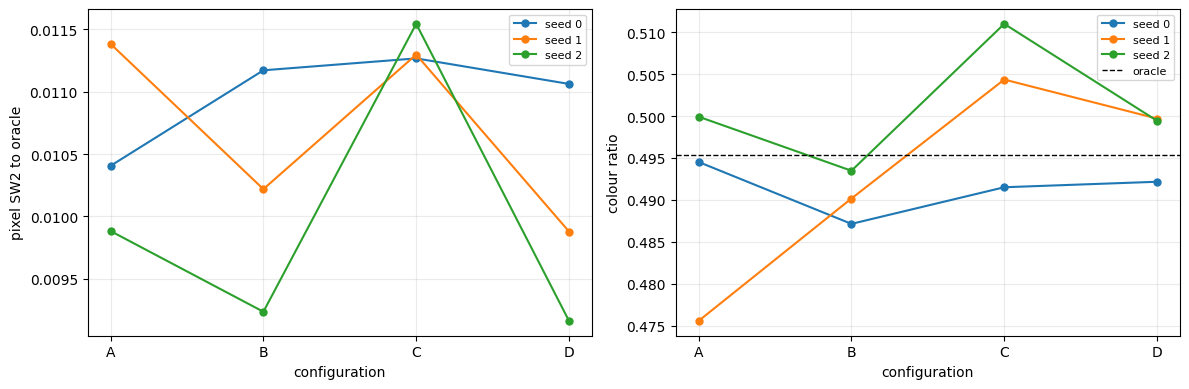

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
order = list(CONFIGS)
for metric, ax, label in (("sw2", axes[0], "pixel SW2 to oracle"),
                          ("colour", axes[1], "colour ratio")):
    for seed in SEEDS:
        values = [per_seed.loc[(name, seed), metric] for name in order]
        ax.plot(range(len(order)), values, marker="o", ms=5, label=f"seed {seed}")
    ax.set_xticks(range(len(order)), [name[:1] for name in order])
    ax.set_xlabel("configuration")
    ax.set_ylabel(label)
    ax.grid(alpha=0.25)
axes[1].axhline(results.colour_oracle.mean(), ls="--", c="k", lw=1, label="oracle")
axes[0].legend(fontsize=8)
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()

## Findings

**The SW2 improvement is not established.** Full-sample Nystrom support gives
$0.0100 \pm 0.0010$ (D) against the baseline's $0.0106 \pm 0.0008$ (A) — a $5\%$
gain inside a $9\%$ standard deviation, and the per-seed panel shows the ordering
*flipping*: seed 0 prefers the baseline, seeds 1 and 2 prefer the Nystrom configs.
Three seeds cannot call a difference this size. Anyone quoting it should run the
multi-seed version first.

**The variance reduction is real and consistent.** On the colour statistic — the
quantity the intervention actually targets — the seed-to-seed spread collapses with
the larger support: $0.490 \pm 0.013$ (A) and $0.502 \pm 0.010$ (C) at
$N_{\mathrm{DR}} = 4000$, against $0.490 \pm 0.003$ (B) and $0.497 \pm 0.004$ (D) on
the full sample. That is a $3$–$4\times$ tightening in the same direction for every
seed, and $\sum_i v_i$ moves from $0.993$ to exactly $1.000$. More support does not
obviously move the estimate; it stops the estimate from wandering.

**D is also closest in level.** Oracle colour is $0.495$; D lands at $0.497$, against
$0.490$ for the baseline and $0.502$ for no-split-alone.

**Dropping the split on its own makes things worse, and that is the useful part.**
Configuration C — no split but still $N_{\mathrm{DR}} = 4000$ — is the weakest on SW2
($0.0114$, matching the main sweep's saturated value) and overshoots the colour law.
It pays the cost of letting the feature map see the estimation rows without
collecting the benefit, because the cap still binds at $4000$. The split was never
the bottleneck; the cap was. Removing the split is only worth it *together* with
using the rows it frees, which is what D does.

**The cost is negligible.** The DR solve goes from $8.0$ s at $N_{\mathrm{DR}} =
4000$ to $19.6$ s on all $20000$ rows — $2.5\times$ the time for $5\times$ the data,
where the exact solver would have needed a $16000 \times 16000$ system per fold.

**What to run next.** A $10$-seed confirmation through the simulation script is the
only way to settle the SW2 question; and since the cap, not the split, is what binds,
an $N_{\mathrm{DR}}$ sweep at fixed $n_{\mathrm{obs}} = 20000$ would show where the
support size stops paying.